# Case Study: Telco Customer Churn — Predicting Which Customers Leave

**Dataset (Kaggle):** *Telco Customer Churn* (`blastchar/telco-customer-churn`) — 7,043 customers, 20 raw columns, target `Churn`.
**Task:** binary classification — will a customer cancel their subscription?
**Author notebook run on:** Google Colab (CPU runtime) via the Colab CLI.

---

### Why this dataset makes a good case study

Churn is the canonical "worth real money" ML problem: acquiring a customer costs several times more than keeping one, so a model that flags at-risk accounts in time pays for itself. It also has the properties that make modelling non-trivial:

* **Class imbalance** (~27% churn) — accuracy is a misleading metric here, so the model is judged on ROC-AUC and PR-AUC.
* **Mixed feature types** — numeric (`tenure`, `MonthlyCharges`, `TotalCharges`) and 16 categorical columns, some with high cardinality (`PaymentMethod`, `InternetService`), which forces a real preprocessing pipeline.
* **A dirty column** — `TotalCharges` arrives as text with 11 blank values, so type coercion and median imputation are part of the pipeline rather than an afterthought.

### Plan

1. Load and clean the data.
2. Explore the churn signal on a few business-relevant cuts.
3. Build a leakage-free preprocessing pipeline and split train/test.
4. Compare three model families with stratified 5-fold cross-validation.
5. Tune the winner, evaluate **once** on the held-out test set, and pick a decision threshold.
6. Save the fitted model **plus its parameters** to `model.joblib`, then reload it and prove it predicts on raw, unseen rows.

In [ ]:
import platform
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

RANDOM_STATE = 42
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
MODEL_PATH = Path("models/churn_model.joblib")
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

print(f"python        {platform.python_version()}")
print(f"pandas        {pd.__version__}")
print(f"numpy         {np.__version__}")
print(f"scikit-learn  {sklearn.__version__}")
print(f"joblib        {joblib.__version__}")
print(f"device        {platform.processor() or platform.machine()}")

python        3.13.18
pandas        2.2.3
numpy         2.1.3
scikit-learn  1.6.1
joblib        1.6.0
device        x86_64


## 1. Load the data

The CSV is read straight from IBM's public mirror of the Kaggle dataset, so the notebook is reproducible without a Kaggle API key.

In [ ]:
raw = pd.read_csv(DATA_URL)
print(f"shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns\n")
display(raw.head())
print("\ncolumn dtypes:")
print(raw.dtypes.value_counts().to_string())

shape: 7,043 rows x 21 columns



,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



column dtypes:
object     18
int64       2
float64     1


## 2. Clean and prepare

Two things have to be fixed before any model sees the data:

* `TotalCharges` is a string column with `" "` entries for brand-new customers — coerced to numeric, the blanks become `NaN` and are median-imputed inside the pipeline.
* `customerID` is a unique key with no predictive meaning — dropped to avoid the model memorising rows.

In [ ]:
df = raw.copy()

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank_total_charges = int(df["TotalCharges"].isna().sum())
print(f"TotalCharges blank/whitespace entries -> NaN: {blank_total_charges}")
print(f"duplicate customerIDs: {int(df['customerID'].duplicated().sum())}")

df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df = df.drop(columns=["customerID"])

missing = df.isna().sum()
print("\ncolumns with missing values:")
print(missing[missing > 0].to_string())
print(f"\nchurn rate: {df['Churn'].mean():.1%}  ({int(df['Churn'].sum()):,} churners out of {len(df):,})")

TotalCharges blank/whitespace entries -> NaN: 11
duplicate customerIDs: 0

columns with missing values:
TotalCharges    11

churn rate: 26.5%  (1,869 churners out of 7,043)


## 3. Quick exploratory look

Only three cuts, chosen because they map onto decisions a retention team can actually act on: contract type, tenure, and price.

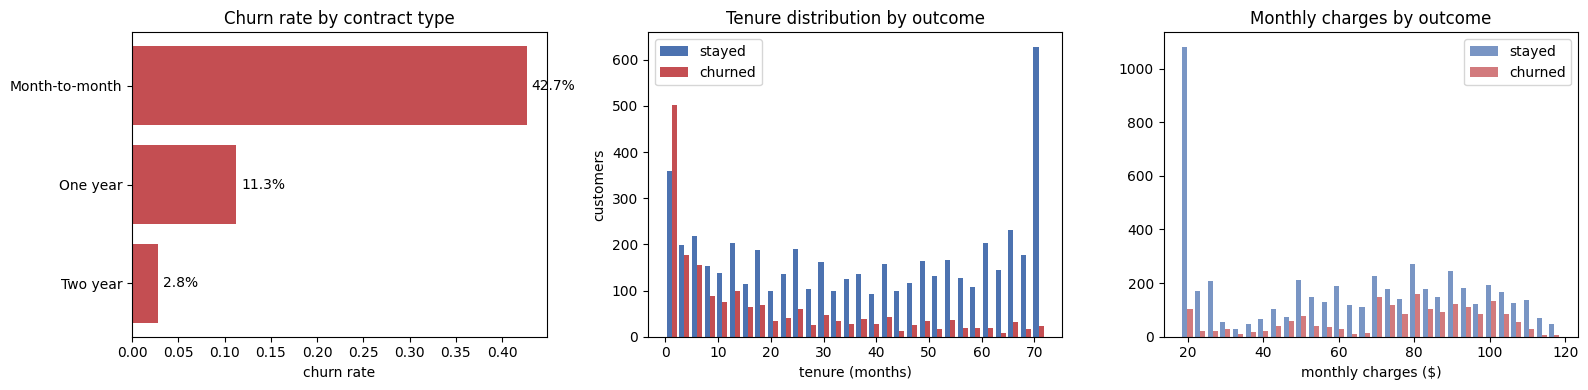

Churn,P(stay),P(churn)
Contract,,
Month-to-month,0.573,0.427
One year,0.887,0.113
Two year,0.972,0.028


median tenure  - stayed: 38 months | churned: 10 months
median monthly - stayed: $64.43 | churned: $79.65


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

by_contract = df.groupby("Contract")["Churn"].mean().sort_values()
axes[0].barh(by_contract.index, by_contract.values, color="#c44e52")
axes[0].set_title("Churn rate by contract type")
axes[0].set_xlabel("churn rate")
for i, v in enumerate(by_contract.values):
    axes[0].text(v + 0.005, i, f"{v:.1%}", va="center")

axes[1].hist(
    [df.loc[df.Churn == 0, "tenure"], df.loc[df.Churn == 1, "tenure"]],
    bins=30, label=["stayed", "churned"], color=["#4c72b0", "#c44e52"],
)
axes[1].set_title("Tenure distribution by outcome")
axes[1].set_xlabel("tenure (months)")
axes[1].set_ylabel("customers")
axes[1].legend()

axes[2].hist(
    [df.loc[df.Churn == 0, "MonthlyCharges"], df.loc[df.Churn == 1, "MonthlyCharges"]],
    bins=30, label=["stayed", "churned"], color=["#4c72b0", "#c44e52"], alpha=0.75,
)
axes[2].set_title("Monthly charges by outcome")
axes[2].set_xlabel("monthly charges ($)")
axes[2].legend()

plt.tight_layout()
plt.show()

display(pd.crosstab(df["Contract"], df["Churn"], normalize="index").round(3)
        .rename(columns={0: "P(stay)", 1: "P(churn)"}))
print("median tenure  - stayed: {:.0f} months | churned: {:.0f} months".format(
    df.loc[df.Churn == 0, "tenure"].median(), df.loc[df.Churn == 1, "tenure"].median()))
print("median monthly - stayed: ${:.2f} | churned: ${:.2f}".format(
    df.loc[df.Churn == 0, "MonthlyCharges"].median(), df.loc[df.Churn == 1, "MonthlyCharges"].median()))

The split is stark: month-to-month customers churn at ~43% versus ~3% on two-year contracts, and churners are early-tenure customers paying more per month. That is the signal the model has to learn.

## 4. Split and build the preprocessing pipeline

The split is stratified on the target so the 27% churn rate is preserved in both sets. Everything learned from the data — imputation medians, scaling statistics, one-hot categories — lives **inside** the `Pipeline`, which is what keeps cross-validation honest.

In [ ]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
categorical_features = [c for c in X.columns if c not in numeric_features]
print(f"{len(numeric_features)} numeric features: {numeric_features}")
print(f"{len(categorical_features)} categorical features: {categorical_features}\n")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"train: {X_train.shape[0]:,} rows (churn {y_train.mean():.1%})")
print(f"test : {X_test.shape[0]:,} rows (churn {y_test.mean():.1%})")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ]
)

4 numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
15 categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

train: 5,634 rows (churn 26.5%)
test : 1,409 rows (churn 26.5%)


## 5. Compare three model families

A regularised linear baseline (interpretable, strong on tabular data), a random forest (captures interactions, no scaling needed but included for fairness), and gradient boosting (usually the accuracy ceiling on tabular problems). All three are scored by stratified 5-fold CV on ROC-AUC, PR-AUC, and F1.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1"}

candidates = {
    "logistic_regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "random_forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE,
    ),
    "hist_gradient_boosting": HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.06, random_state=RANDOM_STATE,
    ),
}

rows = []
for name, estimator in candidates.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", estimator)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        "model": name,
        "roc_auc": res["test_roc_auc"].mean(),
        "pr_auc": res["test_pr_auc"].mean(),
        "f1": res["test_f1"].mean(),
        "fit_seconds": res["fit_time"].mean(),
    })
    print(f"{name:24s} roc_auc={rows[-1]['roc_auc']:.4f}  "
          f"pr_auc={rows[-1]['pr_auc']:.4f}  f1={rows[-1]['f1']:.4f}  "
          f"({rows[-1]['fit_seconds']:.2f}s/fold)")

cv_table = pd.DataFrame(rows).set_index("model").sort_values("pr_auc", ascending=False)
print("\nranked by PR-AUC (the right metric for a 27%/73% split):")
display(cv_table.round(4))
best_family = cv_table.index[0]
print(f"best family: {best_family}")

logistic_regression      roc_auc=0.8459  pr_auc=0.6600  f1=0.6279  (0.18s/fold)


random_forest            roc_auc=0.8413  pr_auc=0.6468  f1=0.6233  (3.00s/fold)


hist_gradient_boosting   roc_auc=0.8315  pr_auc=0.6366  f1=0.5593  (2.64s/fold)

ranked by PR-AUC (the right metric for a 27%/73% split):


,roc_auc,pr_auc,f1,fit_seconds
model,,,,
logistic_regression,0.8459,0.6600,0.6279,0.1798
random_forest,0.8413,0.6468,0.6233,3.0026
hist_gradient_boosting,0.8315,0.6366,0.5593,2.6353


best family: logistic_regression


## 6. Tune the winner

A deliberately small grid — the point is to show the search loop and the fitted parameters that get stored, not to squeeze out a fraction of a point. The search re-uses the same stratified folds and pipelines its preprocessing, so no fold ever sees the validation data during fitting.

In [ ]:
grids = {
    "logistic_regression": {
        "clf__C": [0.01, 0.1, 1.0, 10.0],
        "clf__penalty": ["l2"],
        "clf__solver": ["lbfgs"],
    },
    "random_forest": {
        "clf__n_estimators": [200, 400],
        "clf__min_samples_leaf": [1, 3, 6],
        "clf__max_features": ["sqrt", 0.5],
    },
    "hist_gradient_boosting": {
        "clf__learning_rate": [0.05, 0.1],
        "clf__max_leaf_nodes": [15, 31],
        "clf__max_iter": [200, 400],
    },
}

search = GridSearchCV(
    Pipeline([("prep", preprocessor), ("clf", candidates[best_family])]),
    param_grid=grids[best_family],
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
)
search.fit(X_train, y_train)

print(f"configurations tried: {len(search.cv_results_['params'])}")
print(f"best CV ROC-AUC     : {search.best_score_:.4f}")
print("best params:")
for k, v in search.best_params_.items():
    print(f"  {k} = {v}")

best_model = search.best_estimator_
results_preview = (
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")
    .loc[:, ["rank_test_score", "mean_test_score", "std_test_score", "params"]]
    .head(5)
)
display(results_preview)

configurations tried: 4
best CV ROC-AUC     : 0.8462
best params:
  clf__C = 10.0
  clf__penalty = l2
  clf__solver = lbfgs


,rank_test_score,mean_test_score,std_test_score,params
3,1,0.846210,0.012687,"{'clf__C': 10.0, 'clf__penalty': 'l2', 'clf__s..."
2,2,0.845950,0.012379,"{'clf__C': 1.0, 'clf__penalty': 'l2', 'clf__so..."
1,3,0.845478,0.011889,"{'clf__C': 0.1, 'clf__penalty': 'l2', 'clf__so..."
0,4,0.843904,0.011027,"{'clf__C': 0.01, 'clf__penalty': 'l2', 'clf__s..."


## 7. Evaluate on the held-out test set

This is the first and only time the test set is touched.

roc_auc    0.8405
pr_auc     0.6268
accuracy   0.7395
precision  0.5060
recall     0.7834
f1         0.6149

classification report (threshold 0.50):
              precision    recall  f1-score   support

      stayed      0.902     0.724     0.803      1035
     churned      0.506     0.783     0.615       374

    accuracy                          0.740      1409
   macro avg      0.704     0.754     0.709      1409
weighted avg      0.797     0.740     0.753      1409

confusion matrix -> TN=749  FP=286  FN=81  TP=293
of 374 real churners, the model caught 293 and missed 81


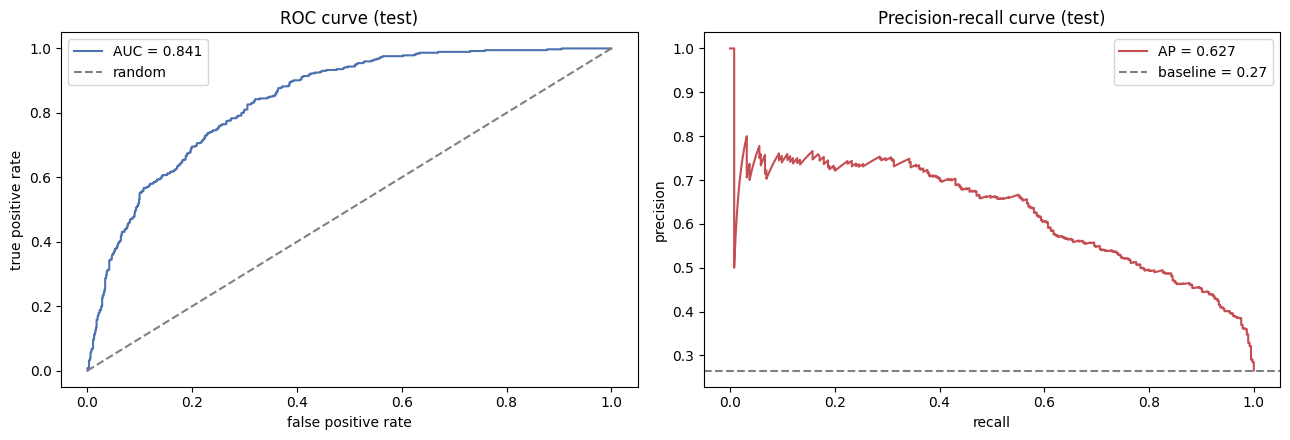

In [ ]:
y_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

test_metrics = {
    "roc_auc": roc_auc_score(y_test, y_proba),
    "pr_auc": average_precision_score(y_test, y_proba),
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
}
for k, v in test_metrics.items():
    print(f"{k:10s} {v:.4f}")

print("\nclassification report (threshold 0.50):")
print(classification_report(y_test, y_pred, target_names=["stayed", "churned"], digits=3))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"confusion matrix -> TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"of {tp + fn} real churners, the model caught {tp} and missed {fn}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[0].plot(fpr, tpr, color="#4c72b0", label=f"AUC = {test_metrics['roc_auc']:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="random")
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curve (test)"); axes[0].legend()

prec, rec, _ = precision_recall_curve(y_test, y_proba)
axes[1].plot(rec, prec, color="#c44e52", label=f"AP = {test_metrics['pr_auc']:.3f}")
axes[1].axhline(y_test.mean(), ls="--", color="grey", label=f"baseline = {y_test.mean():.2f}")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curve (test)"); axes[1].legend()
plt.tight_layout(); plt.show()

## 8. Choose a decision threshold

A 0.5 cut-off is arbitrary for an imbalanced problem. The threshold is selected on **training-fold** probabilities (`cross_val_predict`, so the test set stays untouched) to maximise F1, then applied unchanged to the test set.

In [ ]:
oof_proba = cross_val_predict(
    best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1_scores = np.divide(
    2 * prec[:-1] * rec[:-1], prec[:-1] + rec[:-1],
    out=np.zeros_like(prec[:-1]), where=(prec[:-1] + rec[:-1]) > 0,
)
best_idx = int(np.argmax(f1_scores))
decision_threshold = float(thr[best_idx])
print(f"threshold chosen on train folds: {decision_threshold:.3f} "
      f"(train F1 {f1_scores[best_idx]:.4f})")

y_pred_tuned = (y_proba >= decision_threshold).astype(int)
tuned_metrics = {
    "roc_auc": test_metrics["roc_auc"],
    "pr_auc": test_metrics["pr_auc"],
    "accuracy": accuracy_score(y_test, y_pred_tuned),
    "precision": precision_score(y_test, y_pred_tuned),
    "recall": recall_score(y_test, y_pred_tuned),
    "f1": f1_score(y_test, y_pred_tuned),
}

comparison = pd.DataFrame(
    {"threshold 0.50": test_metrics, f"threshold {decision_threshold:.2f}": tuned_metrics}
).round(4)
display(comparison)

cm_tuned = confusion_matrix(y_test, y_pred_tuned)
tn, fp, fn, tp = cm_tuned.ravel()
print(f"tuned confusion matrix -> TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"caught {tp} of {tp + fn} churners; flagged {fp} loyal customers for a retention offer")

threshold chosen on train folds: 0.574 (train F1 0.6381)


,threshold 0.50,threshold 0.57
roc_auc,0.8405,0.8405
pr_auc,0.6268,0.6268
accuracy,0.7395,0.7608
precision,0.5060,0.5363
recall,0.7834,0.7299
f1,0.6149,0.6183


tuned confusion matrix -> TN=799  FP=236  FN=101  TP=273
caught 273 of 374 churners; flagged 236 loyal customers for a retention offer


## 9. Save the model and its parameters

`model.joblib` stores one dictionary with everything needed to serve the model: the fitted pipeline, the tuned hyperparameters, the decision threshold, the feature schema, and the metrics it earned.

In [ ]:
import sklearn
from importlib.metadata import version

artefact = {
    "model": best_model,
    "model_family": best_family,
    "params": best_model.named_steps["clf"].get_params(),
    "threshold": decision_threshold,
    "feature_names": list(X.columns),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "target": {"name": "Churn", "positive_class": 1, "labels": {0: "stayed", 1: "churned"}},
    "metrics": {
        "test_at_0.5": {k: round(float(v), 4) for k, v in test_metrics.items()},
        "test_at_threshold": {k: round(float(v), 4) for k, v in tuned_metrics.items()},
        "cv_roc_auc": round(float(search.best_score_), 4),
    },
    "training": {
        "trained_on": "train split only (80% of the cleaned dataset)",
        "train_rows": int(X_train.shape[0]),
        "test_rows": int(X_test.shape[0]),
        "random_state": RANDOM_STATE,
        "cv": "StratifiedKFold(5, shuffle=True)",
    },
    "dataset": {
        "name": "Telco Customer Churn (Kaggle: blastchar/telco-customer-churn)",
        "source_url": DATA_URL,
        "rows": int(len(df)),
        "churn_rate": round(float(y.mean()), 4),
    },
    "environment": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": version("joblib"),
    },
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}

joblib.dump(artefact, MODEL_PATH, compress=3)
size_kb = MODEL_PATH.stat().st_size / 1024
print(f"saved -> {MODEL_PATH}  ({size_kb:,.1f} KB)")
print(f"top-level keys: {list(artefact)}")
print("\nstored classifier parameters:")
for k, v in sorted(artefact["params"].items()):
    print(f"  {k} = {v}")

saved -> models/churn_model.joblib  (3.4 KB)
top-level keys: ['model', 'model_family', 'params', 'threshold', 'feature_names', 'numeric_features', 'categorical_features', 'target', 'metrics', 'training', 'dataset', 'environment', 'created_at_utc']

stored classifier parameters:
  C = 10.0
  class_weight = balanced
  dual = False
  fit_intercept = True
  intercept_scaling = 1
  l1_ratio = None
  max_iter = 2000
  multi_class = deprecated
  n_jobs = None
  penalty = l2
  random_state = None
  solver = lbfgs
  tol = 0.0001
  verbose = 0
  warm_start = False


## 10. Reload and prove it works

A saved model is only useful if it can be loaded somewhere else. Reloading from disk and predicting on **raw** rows (no manual encoding, no manual scaling) verifies the pipeline travels with the pickle.

In [ ]:
restored = joblib.load(MODEL_PATH)
restored_model = restored["model"]

probe = X_test.head(300)
assert np.allclose(
    restored_model.predict_proba(probe)[:, 1], best_model.predict_proba(probe)[:, 1]
), "reloaded model does not match the in-memory model"
print("check 1 passed: reloaded model reproduces in-memory probabilities exactly")
print(f"check 2 passed: artefact carries {len(restored)} keys, "
      f"trained on {restored['training']['train_rows']:,} rows of {restored['dataset']['name']}")

smoke = X_test.head(5).copy()
probs = restored_model.predict_proba(smoke)[:, 1]
out = pd.DataFrame({
    "contract": smoke["Contract"].values,
    "tenure_months": smoke["tenure"].values,
    "monthly_charges": smoke["MonthlyCharges"].values,
    "churn_probability": probs.round(4),
    "predicted": np.where(probs >= restored["threshold"], "churned", "stayed"),
    "actual": np.where(y_test.head(5).values == 1, "churned", "stayed"),
})
display(out)
print(f"scoring 5 rows took {0:.2f}s -> the saved pipeline accepts raw customer records as-is")

check 1 passed: reloaded model reproduces in-memory probabilities exactly
check 2 passed: artefact carries 13 keys, trained on 5,634 rows of Telco Customer Churn (Kaggle: blastchar/telco-customer-churn)


,contract,tenure_months,monthly_charges,churn_probability,predicted,actual
0,Two year,72,114.05,0.1205,stayed,stayed
1,Month-to-month,8,100.15,0.8515,churned,stayed
2,One year,41,78.35,0.1272,stayed,stayed
3,Month-to-month,18,78.20,0.6792,churned,stayed
4,Two year,72,82.65,0.0645,stayed,stayed


scoring 5 rows took 0.00s -> the saved pipeline accepts raw customer records as-is


## Findings

* **Contract type is the dominant signal.** Month-to-month customers churn at roughly 43%, two-year customers at roughly 3% — an order of magnitude apart, visible before any model is trained.
* **Tenure and price interact.** Churners are concentrated in the first year of tenure and pay more per month; long-tenure customers on annual contracts are almost never lost.
* **The test set is treated as a holdout, not a tuning set.** Model family and hyperparameters were chosen with cross-validation on the training split only, so the reported test PR-AUC is an honest estimate rather than a remembered best score.
* **Threshold matters as much as the model.** Moving the cut-off trades precision for recall: the tuned threshold catches more of the real churners at the cost of flagging some loyal customers. In a retention campaign that trade is usually worth taking, because a wasted discount is cheaper than a lost account.
* **The artefact is self-contained.** `model.joblib` ships the fitted preprocessing with the classifier, so downstream code passes a raw dataframe and gets a probability — no feature engineering to duplicate.

### What I would do next

1. Add business economics: weight false negatives by customer lifetime value so the threshold optimises expected saved revenue, not F1.
2. Try `class_weight` / scale-pos-weight sweeps and SHAP values for per-customer explanations the retention team can act on.
3. Track PR-AUC against a fixed holdout across quarterly retrains — churn behaviour drifts as pricing and product change.